In [33]:
import csv
import matplotlib.pyplot as plt

In [34]:
with open("motor.csv", "r", newline="") as f:
    motoren = list(csv.DictReader(f))

with open("batterijen.csv", "r", newline="") as f:
    batterijen = list(csv.DictReader(f))

In [35]:
for batterij in batterijen:
    batterij["Aantal stuks"] = int(float(batterij["Echt prijs"])/float(batterij["Prijs/stuk"]))

In [36]:
def isclose(a, b, rel_tol=1e-09, abs_tol=0.0):
    return abs(a-b) <= max(rel_tol * max(abs(a), abs(b)), abs_tol)

In [37]:
def combo_mogelijk(batterij, motor):
    if not isclose(float(motor["Voltage (V)"]), float(batterij["Voltage (V)"])):
        return False
    return True

In [38]:
opties = []
for batterij in batterijen:
    for motor in motoren:
        if combo_mogelijk(batterij, motor):
            opties += [(float(batterij["Echt prijs"]) + float(motor["Prijs"]), float(motor["Vaartijd per WH (sec)"]) * float(batterij["WH"]),batterij, motor)]

In [39]:
len(opties)

67

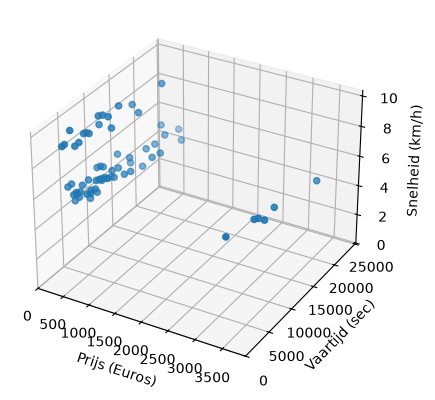

In [49]:
# Plot
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.scatter(
    list(map(lambda x:x[0], opties)),
    list(map(lambda x:x[1], opties)),
    list(map(lambda x:float(x[3]["Snelheid (km/h)"]), opties))
)
ax.axes.xaxis.set_label_text("Prijs (Euros)")
ax.axes.yaxis.set_label_text("Vaartijd (sec)")
ax.axes.zaxis.set_label_text("Snelheid (km/h)")
ax.set_xlim(xmin=0)
ax.set_ylim(ymin=0)
ax.set_zlim(zmin=0)
fig.show()